# B30 怎样独立完成可复现、可交接的预测项目？

任务：用真实 UCI 小时单车记录预测下一小时需求，完成数据契约、时序评价、模型交接与本地接口。先阅读独立任务书，再对照参考实现。

先修：B01—B29；重点 B15、B27—B29。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 明确预测时点并读取真实数据
在目标小时t开始前预测cnt；只使用日历信息与t−24、t−168小时已观测需求。实际天气、casual和registered均禁止作输入。原数据有缺失小时，先补齐时间索引，再shift，避免把24条记录误作24小时。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

import hashlib
import pandas as pd
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
data_path = COURSE_ROOT / 'assets/data/bike_hour.csv'
if not data_path.is_file():
    raise FileNotFoundError(f'缺少离线 UCI 数据：{data_path}')
raw = pd.read_csv(data_path)
required = {'dteday', 'hr', 'cnt', 'holiday', 'workingday'}
assert required.issubset(raw.columns)
raw['timestamp'] = pd.to_datetime(raw['dteday']) + pd.to_timedelta(raw['hr'], unit='h')
assert not raw['timestamp'].duplicated().any()
hourly = raw.set_index('timestamp').sort_index().reindex(pd.date_range(raw['timestamp'].min(), raw['timestamp'].max(), freq='h'))
print('原记录', len(raw), '缺失小时', int(hourly['cnt'].isna().sum()))

原记录 17379 缺失小时 165


## 2. 只构造当时可用特征
shift(24)先移位再取值，绝不能使用未来信息补齐历史。缺少目标或历史滞后值的行删除并报告。按时间70%/15%/15%分割；测试阶段是逐小时滚动预测，可使用当时已发生的早期测试需求，不是固定起点预测整季。

In [3]:
frame = pd.DataFrame(index=hourly.index)
frame['hour'] = frame.index.hour
frame['weekday'] = frame.index.dayofweek
frame['month'] = frame.index.month
frame['year_index'] = frame.index.year - 2011
frame['holiday'] = hourly['holiday']
frame['workingday'] = hourly['workingday']
frame['lag24'] = hourly['cnt'].shift(24)
frame['lag168'] = hourly['cnt'].shift(168)
frame['target'] = hourly['cnt']
frame = frame.dropna()
features = ['hour', 'weekday', 'month', 'year_index', 'holiday', 'workingday', 'lag24', 'lag168']
forbidden = {'cnt', 'casual', 'registered', 'instant', 'temp', 'atemp', 'hum', 'windspeed', 'weathersit'}
assert not set(features) & forbidden
n = len(frame)
a = int(0.7 * n)
b = int(0.85 * n)
train, validation, test = (frame.iloc[:a], frame.iloc[a:b], frame.iloc[b:])
assert train.index.max() < validation.index.min() < test.index.min()
assert len(test) > 100

## 3. 验证集选择简单模型与实用模型
基线是昨天同一小时需求；另比较 Ridge 和 HistGradientBoosting。固定候选与预算，验证集按MAE选方案，再在训练+验证上重拟合一次。最终测试不参与选择。

In [4]:
candidates = {'ridge': make_pipeline(StandardScaler(), Ridge(alpha=10)), 'hist_gradient_boosting': HistGradientBoostingRegressor(max_iter=110, max_leaf_nodes=15, l2_regularization=2, early_stopping=False, random_state=30)}
validation_scores = {}
for name, candidate in candidates.items():
    candidate.fit(train[features], train['target'])
    validation_scores[name] = float(mean_absolute_error(validation['target'], np.maximum(0, candidate.predict(validation[features]))))
selected = min(validation_scores, key=validation_scores.get)
model = candidates[selected]
development = frame.iloc[:b]
model.fit(development[features], development['target'])
predicted = np.maximum(0, model.predict(test[features]))
baseline = test['lag24'].to_numpy()
model_mae = float(mean_absolute_error(test['target'], predicted))
baseline_mae = float(mean_absolute_error(test['target'], baseline))
rmse = float(np.sqrt(mean_squared_error(test['target'], predicted)))

## 4. 保存可交接结果、错误与模型卡
记录完整数据哈希、日期范围、输入列和预测口径。图展示测试开头168个小时，误差表覆盖全部测试。改善必须来自实际计算；疫情、城市与用户变化不在此历史数据保证内。

In [5]:
result = test[['target', 'lag24']].copy()
result['prediction'] = predicted
result['absolute_error'] = np.abs(result['target'] - predicted)
result.to_csv(OUT_DIR / 'predictions.csv', encoding='utf-8-sig', index_label='timestamp')
bundle = {'model': model, 'features': features, 'selected': selected}
joblib.dump(bundle, OUT_DIR / 'model.joblib')
metadata = {'dataset': 'UCI Bike Sharing hourly', 'sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(), 'features': features, 'excluded': sorted(forbidden), 'train_end': str(train.index.max()), 'validation_end': str(validation.index.max()), 'test_start': str(test.index.min()), 'test_end': str(test.index.max()), 'forecast_protocol': 'one-hour-ahead rolling; lag24 and lag168 already observed; no observed future weather', 'selected': selected, 'validation_mae': validation_scores}
(OUT_DIR / 'model_card.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
fig, ax = plt.subplots(figsize=(10, 4))
sample = result.iloc[:168]
ax.plot(sample.index, sample['target'], label='真实')
ax.plot(sample.index, sample['prediction'], label='预测')
ax.legend()
ax.set_title('独立测试最初168个可评价小时')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT_DIR / 'forecast.png')
plt.close(fig)
print('最差的五个小时', result.nlargest(5, 'absolute_error')[['target', 'prediction', 'absolute_error']])

最差的五个小时                      target  prediction  absolute_error
2012-10-02 08:00:00   134.0  779.359585      645.359585
2012-09-18 17:00:00   338.0  857.571973      519.571973
2012-11-23 08:00:00    94.0  601.184708      507.184708
2012-09-18 18:00:00   281.0  774.339745      493.339745
2012-12-26 08:00:00    31.0  502.179592      471.179592


## 5. 接口验证与完整项目验收
API 接收已在外部准备好的日历与历史滞后值，拒绝负需求和额外字段。服务不偷偷回看未来CSV。用测试中一条记录核对批预测和API输出一致。

In [6]:
from fastapi import FastAPI
from pydantic import BaseModel, Field, ConfigDict

class BikeRequest(BaseModel):
    model_config = ConfigDict(extra='forbid', allow_inf_nan=False)
    hour: int = Field(ge=0, le=23)
    weekday: int = Field(ge=0, le=6)
    month: int = Field(ge=1, le=12)
    year_index: int = Field(ge=0, le=20)
    holiday: int = Field(ge=0, le=1)
    workingday: int = Field(ge=0, le=1)
    lag24: float = Field(ge=0)
    lag168: float = Field(ge=0)

def create_bike_app(bundle):
    app = FastAPI(title='小时单车需求教学 API')

    @app.get('/health')
    def health():
        return {'status': 'ok', 'model': bundle['selected']}

    @app.post('/predict')
    def predict(payload: BikeRequest):
        row = pd.DataFrame([payload.model_dump()])[bundle['features']]
        prediction = max(0.0, float(bundle['model'].predict(row)[0]))
        return {'predicted_rentals': round(prediction, 2), 'unit': '次/小时', 'horizon': 'one-hour-ahead rolling'}
    return app
from fastapi.testclient import TestClient
app = create_bike_app(bundle)
payload = test[features].iloc[0].to_dict()
for key in ['hour', 'weekday', 'month', 'year_index', 'holiday', 'workingday']:
    payload[key] = int(payload[key])
with TestClient(app) as client:
    response = client.post('/predict', json=payload)
    invalid = client.post('/predict', json={**payload, 'lag24': -1})
assert response.status_code == 200 and invalid.status_code == 422
assert abs(response.json()['predicted_rentals'] - predicted[0]) < 0.011
finish({'raw_rows': len(raw), 'usable_rows': len(frame), 'test_rows': len(test), 'selected_model': selected, 'validation_mae': validation_scores, 'test_mae': model_mae, 'yesterday_baseline_mae': baseline_mae, 'test_rmse': rmse, 'relative_mae_change': (baseline_mae - model_mae) / baseline_mae, 'api_status': response.status_code, 'invalid_api_status': invalid.status_code, 'leakage_columns_excluded': True})

{
  "raw_rows": 17379,
  "usable_rows": 16950,
  "test_rows": 2543,
  "selected_model": "hist_gradient_boosting",
  "validation_mae": {
    "ridge": 58.90707101568961,
    "hist_gradient_boosting": 53.68451649707337
  },
  "test_mae": 55.29867861252311,
  "yesterday_baseline_mae": 77.56940621313409,
  "test_rmse": 86.64522709073388,
  "relative_mae_change": 0.2871071043062862,
  "api_status": 200,
  "invalid_api_status": 422,
  "leakage_columns_excluded": true,
  "elapsed_seconds": 1.407
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

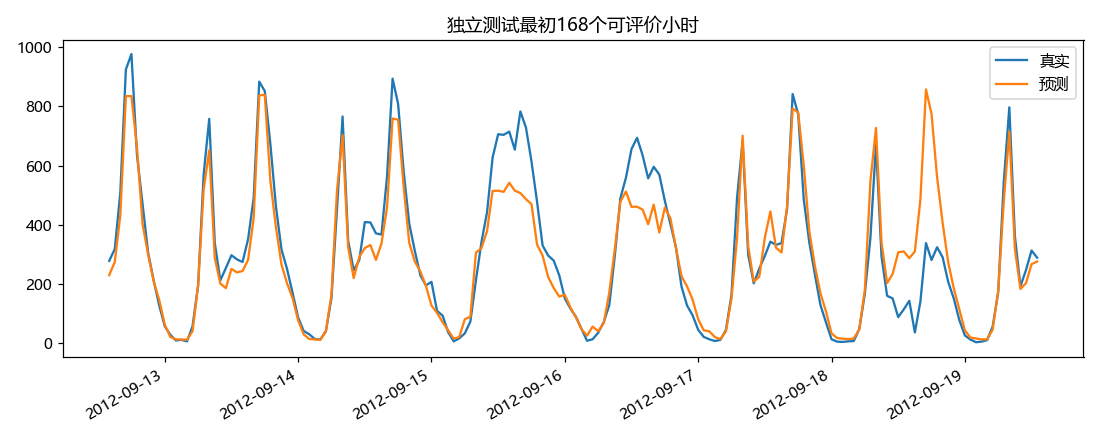

In [7]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
没有未来天气预报数据，因此不使用实际天气字段。测试采用滚动单步协议；不能把该结果描述为固定起点的长期预测。真实部署需重新校准监测阈值。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。